# LAB 05 - Bài 23: Learning Curves

Notebook huấn luyện Simple RNN trên IMDb, ghi training loss và validation loss theo epoch, rồi vẽ biểu đồ. Hãy xem diễn biến qua các epoch để nhận xét overfitting; không chỉ nhìn epoch cuối.

Chạy các cell theo thứ tự. Lần đầu cần Internet để tải ACL IMDb (~84 MB). Bảng CSV và hình PNG được lưu trong `/content`.

In [1]:
# ============================================================
# BÀI 23 - LEARNING CURVES: CHUẨN BỊ IMDb TRAIN/VALIDATION
# ============================================================

from pathlib import Path
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
DATA_DIR = Path("/content/aclImdb")
ARCHIVE_PATH = Path("/content/aclImdb_v1.tar.gz")

if not (DATA_DIR / "train" / "pos").exists():
    if not ARCHIVE_PATH.exists():
        print("Đang tải ACL IMDb từ Stanford (~84 MB)...")
        urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH)
    print("Đang giải nén dataset...")
    with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
        archive.extractall(path="/content")

# Tập train gốc được chia tiếp thành train và validation.
train_texts_all, labels_all = [], []
for label_name, label_id in (("neg", 0), ("pos", 1)):
    folder = DATA_DIR / "train" / label_name
    for file_path in sorted(folder.glob("*.txt")):
        train_texts_all.append(file_path.read_text(encoding="utf-8", errors="replace").strip())
        labels_all.append(label_id)
labels_all = np.asarray(labels_all, dtype=np.int32)

train_texts, val_texts, y_train, y_val = train_test_split(
    train_texts_all,
    labels_all,
    test_size=0.1,
    random_state=42,
    stratify=labels_all,
)

MAX_VOCAB_SIZE = 20_000
MAX_LEN = 200
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 8
SEED = 42

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)

X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN,
                        padding="post", truncating="post")
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN,
                      padding="post", truncating="post")

print("Vocabulary size:", vocab_size)
print("Train shape:", X_train.shape, "Validation shape:", X_val.shape)


Đang tải ACL IMDb từ Stanford (~84 MB)...
Đang giải nén dataset...


/tmp/ipykernel_927/3814854948.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(path="/content")


Vocabulary size: 20000
Train shape: (22500, 200) Validation shape: (2500, 200)


Epoch 1/8
352/352 - 40s - 113ms/step - accuracy: 0.5916 - loss: 0.6646 - val_accuracy: 0.5936 - val_loss: 0.6629
Epoch 2/8
352/352 - 37s - 105ms/step - accuracy: 0.7584 - loss: 0.5125 - val_accuracy: 0.7856 - val_loss: 0.4868
Epoch 3/8
352/352 - 41s - 116ms/step - accuracy: 0.8198 - loss: 0.4110 - val_accuracy: 0.8000 - val_loss: 0.4699
Epoch 4/8
352/352 - 40s - 115ms/step - accuracy: 0.7493 - loss: 0.4966 - val_accuracy: 0.6316 - val_loss: 0.6388
Epoch 5/8
352/352 - 40s - 114ms/step - accuracy: 0.8012 - loss: 0.4243 - val_accuracy: 0.7856 - val_loss: 0.6000
Epoch 6/8
352/352 - 38s - 107ms/step - accuracy: 0.8890 - loss: 0.2825 - val_accuracy: 0.7988 - val_loss: 0.5875
Epoch 7/8
352/352 - 38s - 107ms/step - accuracy: 0.9197 - loss: 0.2188 - val_accuracy: 0.8128 - val_loss: 0.5906
Epoch 8/8
352/352 - 41s - 115ms/step - accuracy: 0.8070 - loss: 0.4263 - val_accuracy: 0.6436 - val_loss: 0.6900

Learning curves theo epoch:
 Epoch  Train Loss  Validation Loss
     1      0.6646           0.

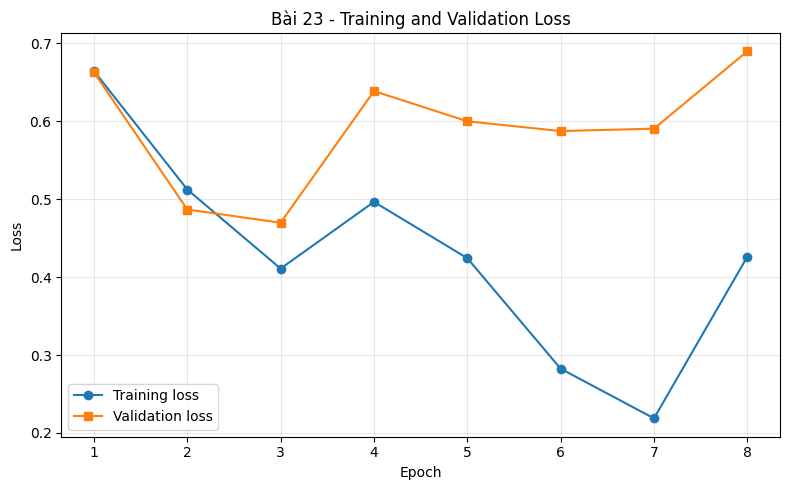

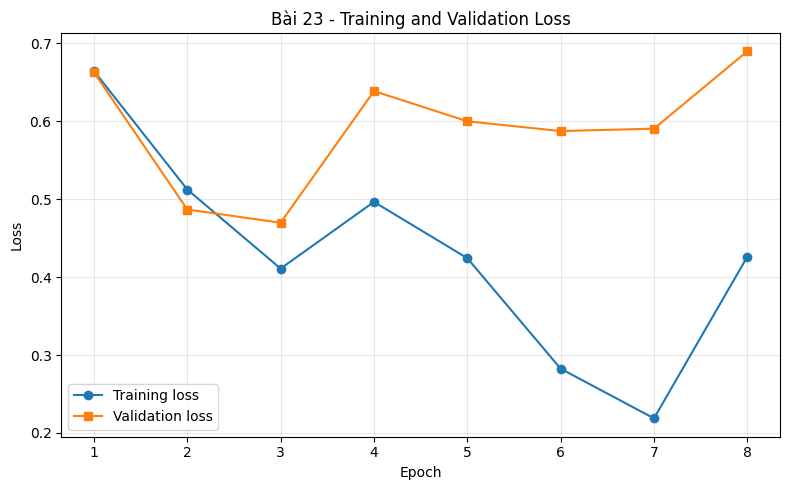

Đã lưu bảng: /content/lab05_bai23_learning_curves.csv
Đã lưu biểu đồ: /content/lab05_bai23_learning_curves.png

Validation loss thấp nhất ở epoch: 3
Train loss epoch cuối: 0.4263
Validation loss epoch cuối: 0.69
Đánh giá overfitting bằng cách xem train loss có giảm trong khi validation loss tăng sau epoch tốt nhất hay không.


In [2]:
# ============================================================
# BÀI 23 - HUẤN LUYỆN VÀ VẼ TRAINING / VALIDATION LOSS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

# Simple RNN classifier dùng để ghi learning curves.
tf.keras.utils.set_random_seed(SEED)
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(vocab_size, EMBEDDING_DIM, mask_zero=True),
    layers.SimpleRNN(HIDDEN_SIZE),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2,
)

# Bảng loss theo epoch.
learning_curve_df = pd.DataFrame({
    "Epoch": range(1, len(history.history["loss"]) + 1),
    "Train Loss": history.history["loss"],
    "Validation Loss": history.history["val_loss"],
})
print("\nLearning curves theo epoch:")
print(learning_curve_df.round(4).to_string(index=False))

# Vẽ cả hai loss trên cùng biểu đồ.
plt.figure(figsize=(8, 5))
plt.plot(learning_curve_df["Epoch"], learning_curve_df["Train Loss"], marker="o", label="Training loss")
plt.plot(learning_curve_df["Epoch"], learning_curve_df["Validation Loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Bài 23 - Training and Validation Loss")
plt.xticks(learning_curve_df["Epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Lưu bảng và hình để dùng trong báo cáo.
CSV_PATH = "/content/lab05_bai23_learning_curves.csv"
PNG_PATH = "/content/lab05_bai23_learning_curves.png"
learning_curve_df.to_csv(CSV_PATH, index=False)
plt.figure(figsize=(8, 5))
plt.plot(learning_curve_df["Epoch"], learning_curve_df["Train Loss"], marker="o", label="Training loss")
plt.plot(learning_curve_df["Epoch"], learning_curve_df["Validation Loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Bài 23 - Training and Validation Loss")
plt.xticks(learning_curve_df["Epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PNG_PATH, dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu bảng:", CSV_PATH)
print("Đã lưu biểu đồ:", PNG_PATH)

best_epoch = int(learning_curve_df["Validation Loss"].idxmin() + 1)
print("\nValidation loss thấp nhất ở epoch:", best_epoch)
print("Train loss epoch cuối:", round(float(learning_curve_df['Train Loss'].iloc[-1]), 4))
print("Validation loss epoch cuối:", round(float(learning_curve_df['Validation Loss'].iloc[-1]), 4))
print("Đánh giá overfitting bằng cách xem train loss có giảm trong khi validation loss tăng sau epoch tốt nhất hay không.")
